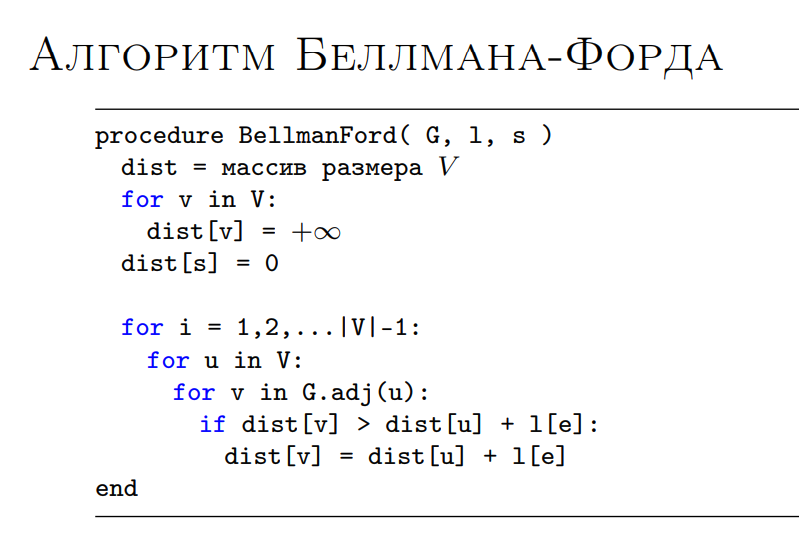

http://ti.math.msu.su/wiki/lib/exe/fetch.php?media=algo:algo-20.pdf

In [13]:
def bellman_ford(g, start):
    """
    g[u][v] = None или вес 
    Возвращает (расстояния, путь до вершины). Если есть отрицательный цикл вернет (None, None).
    """
    n = len(g)
    INF = float("inf")
    dists = {i: INF for i in range(n)}
    route = {i: None for i in range(n)}
    dists[start] = 0
    
    edges = []
    for u in range(n):
        for v in range(n):
            if g[u][v] is not None:
                edges.append((u, v, g[u][v])) #(ребро1, ребро2, вес)

    for _ in range(n - 1):
        updated = False #флаг посетили ли
        for u, v, w in edges:
            if dists[u] != INF and dists[u] + w < dists[v]:
                dists[v] = dists[u] + w
                route[v] = u
                updated = True
        if not updated:
            break

    #если что-то ещё улучшается, то отрицательный цикл
    for u, v, w in edges:
        if dists[u] != INF and dists[u] + w < dists[v]:
            return None, None

    return dists, route

In [14]:
n = 5
g1 = [[None]*n for _ in range(n)]
g1[0][1] = g1[1][0] = 1
g1[1][2] = g1[2][1] = 2
g1[1][3] = g1[3][1] = 3
g1[0][4] = g1[4][0] = 4
g1[0][3] = g1[3][0] = 5

d, r = bellman_ford(g1, 0)
d,r

({0: 0, 1: 1, 2: 3, 3: 4, 4: 4}, {0: None, 1: 0, 2: 1, 3: 1, 4: 0})

In [15]:
g2 = [[None]*n for _ in range(n)]
g2[0][1] = 1
g2[1][0] = -2       
g2[1][2] = g2[2][1] = 2
g2[1][3] = g2[3][1] = 3
g2[0][4] = g2[4][0] = 4
g2[0][3] = g2[3][0] = 5

d, r = bellman_ford(g2, 0)
d,r      

(None, None)